Finance & Economics

In [2]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "finance_economics_dataset.csv"

# Load the latest version using dataset_load
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "khushikyad001/finance-and-economics-dataset-2000-present",
  file_path
)

print("First 5 records:")
print(df.head())

100%|██████████| 470k/470k [00:00<00:00, 77.4MB/s]

First 5 records:
         Date Stock Index  Open Price  Close Price  Daily High  Daily Low  \
0  2000-01-01   Dow Jones     2128.75      2138.48     2143.70    2100.55   
1  2000-01-02     S&P 500     2046.82      2036.18     2082.83    2009.53   
2  2000-01-03   Dow Jones     1987.92      1985.26     2022.28    1978.37   
3  2000-01-04   Dow Jones     4625.02      4660.47     4665.26    4595.46   
4  2000-01-05     S&P 500     1998.18      1982.18     2044.31    1966.44   

   Trading Volume  GDP Growth (%)  Inflation Rate (%)  Unemployment Rate (%)  \
0         2670411           -0.37                6.06                   6.10   
1       690220415            3.19                4.95                   6.62   
2       315284661            5.54                9.13                   2.60   
3        13098297           10.00                3.77                   2.20   
4       385306746            1.53                2.20                   8.20   

   ...  Forex USD/EUR  Forex USD/JPY  C

Handle missing values, duplicates, and ensure consistent date formatting.

In [3]:
import pandas as pd

# 1. Standardize and format the Date column
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# 2. Check for missing values
missing_values = df.isnull().sum()
print("--- Missing Values Per Column ---")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found!")
print()

# 3. Check and handle duplicate rows
duplicate_count = df.duplicated().sum()
print(f"--- Duplicate Rows found: {duplicate_count} ---")
if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
print()

# Display DataFrame summary and the first few rows
print("--- Cleaned Dataset Info ---")
display(df.info())
display(df.head())

--- Missing Values Per Column ---
No missing values found!

--- Duplicate Rows found: 0 ---

--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Date                                   3000 non-null   datetime64[ns]
 1   Stock Index                            3000 non-null   object        
 2   Open Price                             3000 non-null   float64       
 3   Close Price                            3000 non-null   float64       
 4   Daily High                             3000 non-null   float64       
 5   Daily Low                              3000 non-null   float64       
 6   Trading Volume                         3000 non-null   int64         
 7   GDP Growth (%)                         3000 non-null   float64       
 8   Inflation Rate (

None

,Date,Stock Index,Open Price,Close Price,Daily High,Daily Low,Trading Volume,GDP Growth (%),Inflation Rate (%),Unemployment Rate (%),...,Forex USD/EUR,Forex USD/JPY,Crude Oil Price (USD per Barrel),Gold Price (USD per Ounce),Real Estate Index,Retail Sales (Billion USD),Bankruptcy Rate (%),Mergers & Acquisitions Deals,Venture Capital Funding (Billion USD),Consumer Spending (Billion USD)
0,2000-01-01,Dow Jones,2128.75,2138.48,2143.70,2100.55,2670411,-0.37,6.06,6.10,...,1.04,119.87,47.20,1052.34,390.23,2229,2.12,3,76.64,4589
1,2000-01-02,S&P 500,2046.82,2036.18,2082.83,2009.53,690220415,3.19,4.95,6.62,...,1.00,98.22,52.84,1957.73,346.23,4156,1.40,21,5.67,10101
2,2000-01-03,Dow Jones,1987.92,1985.26,2022.28,1978.37,315284661,5.54,9.13,2.60,...,0.83,80.13,78.80,2339.49,439.46,340,0.79,48,39.43,13665
3,2000-01-04,Dow Jones,4625.02,4660.47,4665.26,4595.46,13098297,10.00,3.77,2.20,...,0.95,149.15,28.18,1308.54,213.07,8456,4.22,16,12.83,5192
4,2000-01-05,S&P 500,1998.18,1982.18,2044.31,1966.44,385306746,1.53,2.20,8.20,...,1.43,113.71,92.20,2210.08,405.49,1596,2.21,34,86.37,10688


Exploratory Data Analysis

/tmp/ipykernel_2620/2355021094.py:14: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly = df_sorted.select_dtypes(include=['float64', 'int64']).resample('M').mean().reset_index()
/tmp/ipykernel_2620/2355021094.py:17: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_stock_monthly = df_sorted.groupby(['Stock Index', pd.Grouper(freq='M')])['Close Price'].mean().reset_index()


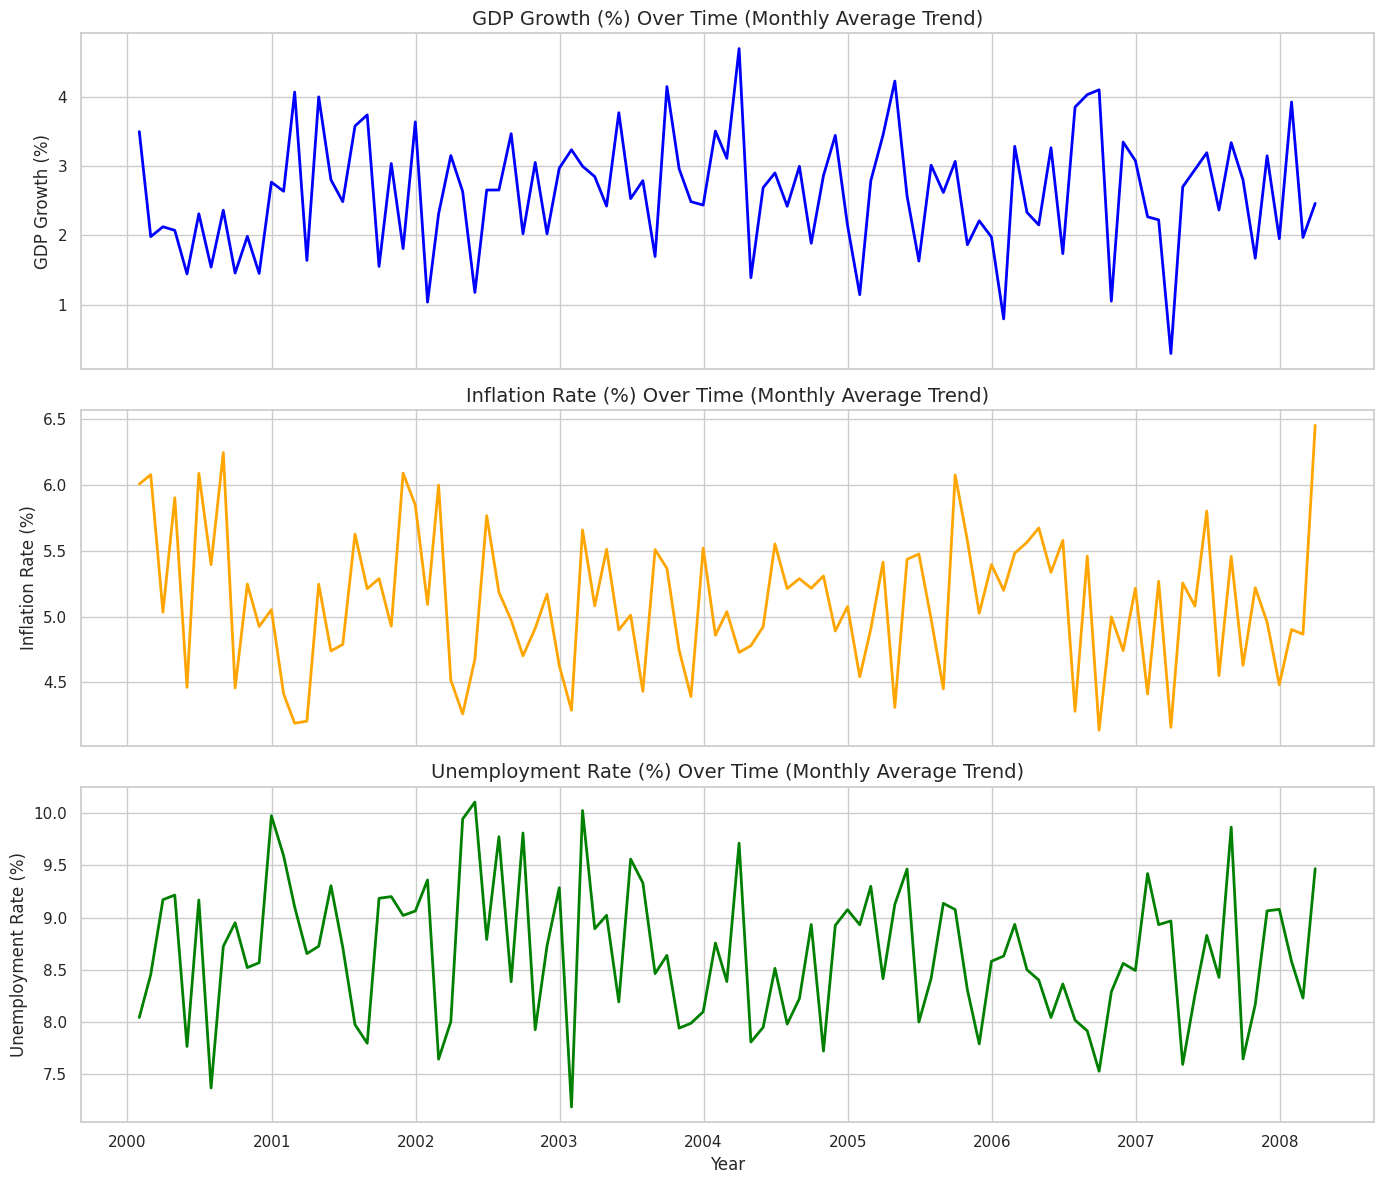

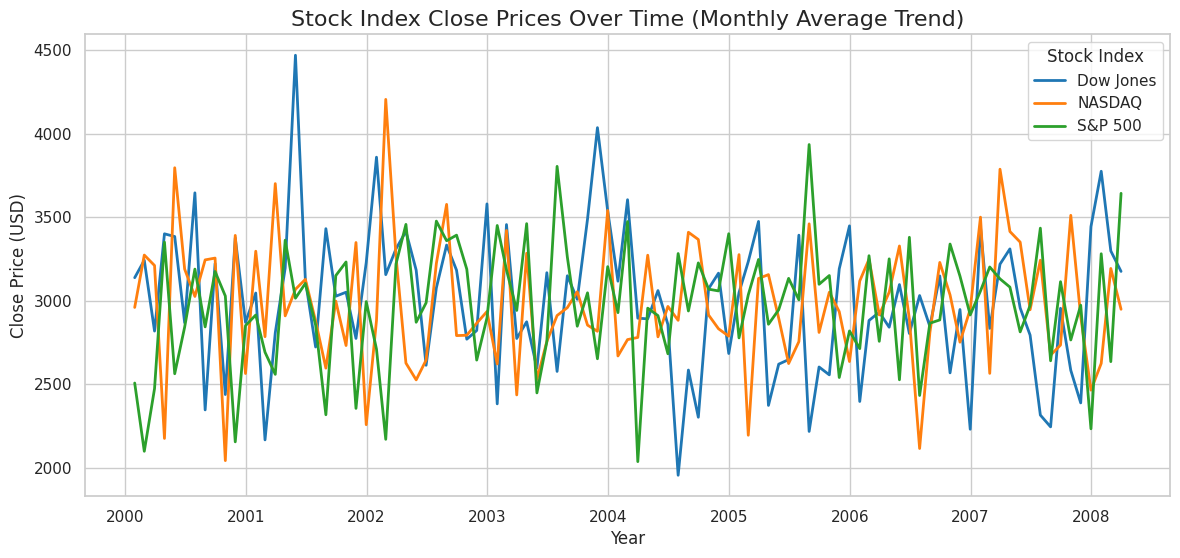

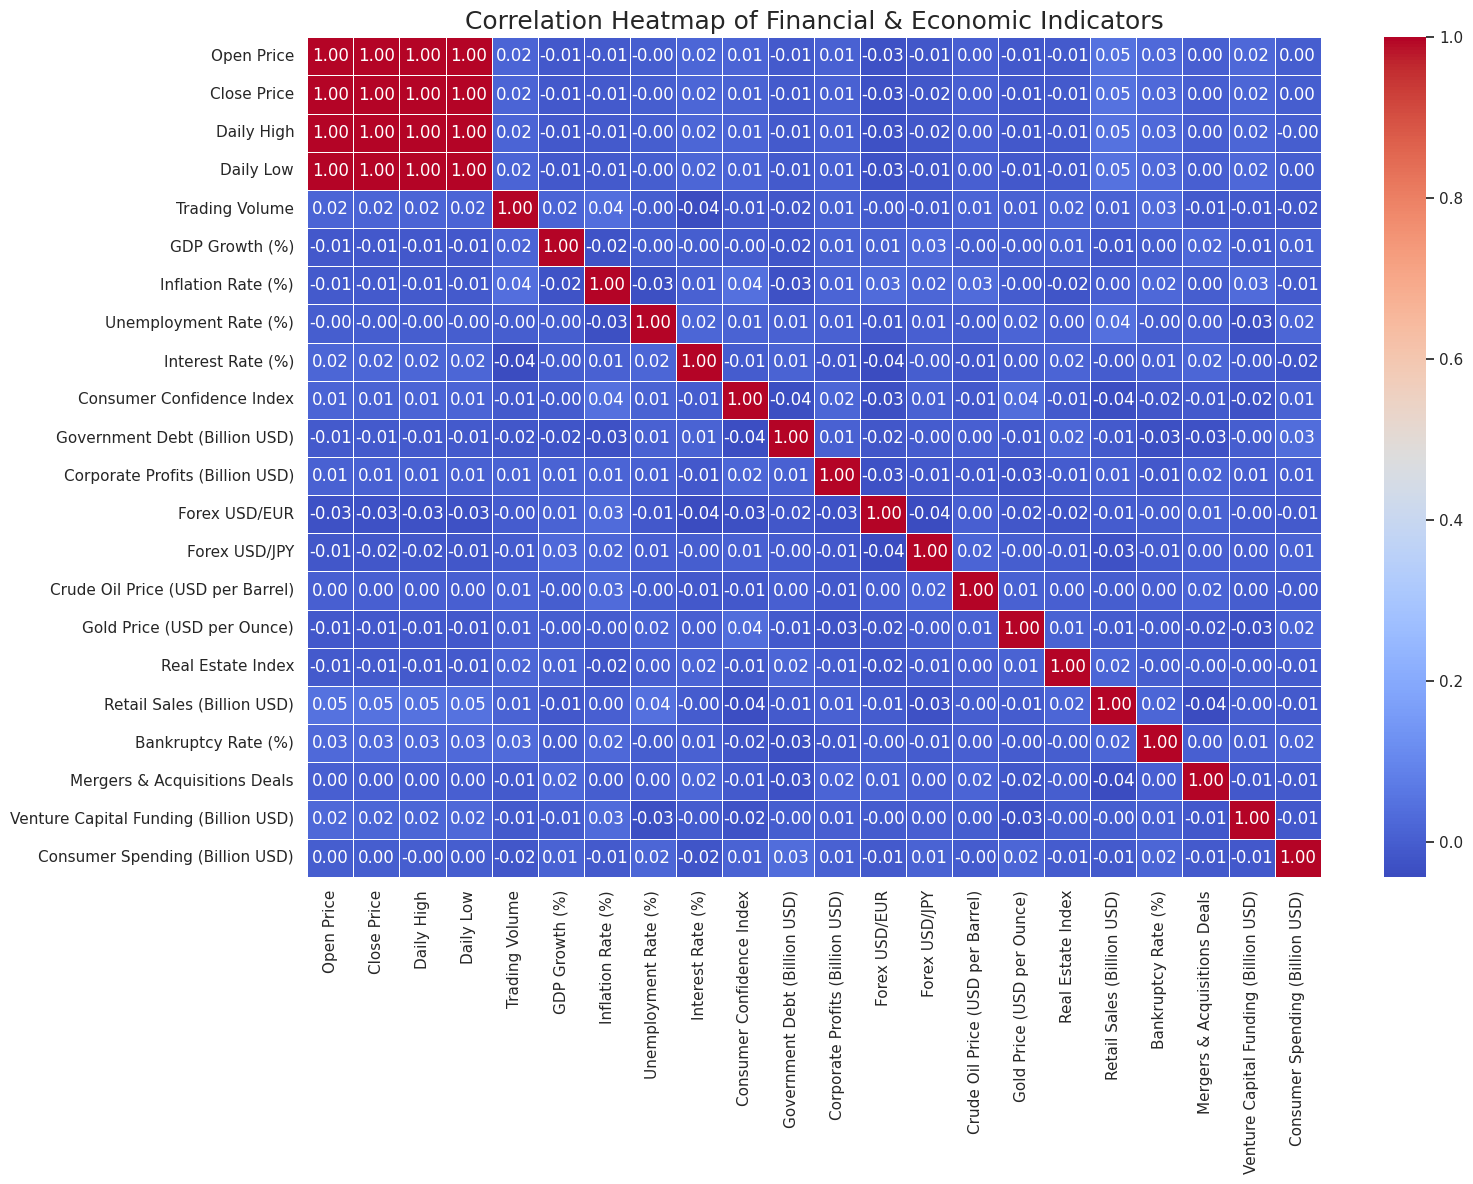

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn style for clean visualizations
sns.set_theme(style="whitegrid")

# Sort by Date to ensure proper chronological order
df_sorted = df.sort_values('Date').copy()

# Set Date as index to easily resample the data
df_sorted.set_index('Date', inplace=True)

# Resample the numerical columns by Month ('M') and take the mean to smooth out the daily noise
df_monthly = df_sorted.select_dtypes(include=['float64', 'int64']).resample('M').mean().reset_index()

# For categorical columns like 'Stock Index', we will group by Month and Stock Index
df_stock_monthly = df_sorted.groupby(['Stock Index', pd.Grouper(freq='M')])['Close Price'].mean().reset_index()

# --- 1. Plot Smoothed Macroeconomic Trends over Time ---
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

sns.lineplot(data=df_monthly, x='Date', y='GDP Growth (%)', ax=axes[0], color='blue', linewidth=2)
axes[0].set_title('GDP Growth (%) Over Time (Monthly Average Trend)', fontsize=14)
axes[0].set_ylabel('GDP Growth (%)')

sns.lineplot(data=df_monthly, x='Date', y='Inflation Rate (%)', ax=axes[1], color='orange', linewidth=2)
axes[1].set_title('Inflation Rate (%) Over Time (Monthly Average Trend)', fontsize=14)
axes[1].set_ylabel('Inflation Rate (%)')

sns.lineplot(data=df_monthly, x='Date', y='Unemployment Rate (%)', ax=axes[2], color='green', linewidth=2)
axes[2].set_title('Unemployment Rate (%) Over Time (Monthly Average Trend)', fontsize=14)
axes[2].set_ylabel('Unemployment Rate (%)')
axes[2].set_xlabel('Year')

plt.tight_layout()
plt.show()

# --- 2. Plot Smoothed Stock Close Prices by Index ---
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_stock_monthly, x='Date', y='Close Price', hue='Stock Index', palette='tab10', linewidth=2)
plt.title('Stock Index Close Prices Over Time (Monthly Average Trend)', fontsize=16)
plt.xlabel('Year')
plt.ylabel('Close Price (USD)')
plt.legend(title='Stock Index')
plt.show()

# --- 3. Correlation Heatmap of Key Indicators ---
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Financial & Economic Indicators', fontsize=18)
plt.tight_layout()
plt.show()

As of now there doesn't seem to be much correlation between variables nor clear monthly trends.

In [ ]:
# DEBUG to find correct filename
# import kagglehub
# import os

# # Download the dataset and get the path to the folder
# path = kagglehub.dataset_download("khushikyad001/finance-and-economics-dataset-2000-present")
# print("Dataset downloaded to:", path)

# # List all files inside the downloaded folder to find the file we want to load
# print("Files inside the dataset:")
# for root, dirs, files in os.walk(path):
#     for file in files:
#         print(os.path.join(root, file))

Using Colab cache for faster access to the 'finance-and-economics-dataset-2000-present' dataset.
Dataset downloaded to: /kaggle/input/finance-and-economics-dataset-2000-present
Files inside the dataset:
/kaggle/input/finance-and-economics-dataset-2000-present/finance_economics_dataset.csv


testing abc